# [LAB-09]  2. 데이터 시각화

## #01. 준비작업

### 1. 라이브러리 참조

In [1]:
from hossam import load_data
from helpers import *

import seaborn as sb
import os
import pandas as pd
import numpy as np
from pandas import DataFrame, Series, concat, merge
from IPython.display import display, Markdown
from sklearn.metrics import silhouette_score

📦 아이티윌 이광호 강사가 제작한 라이브러리를 사용중입니다.
📚 자세한 사용 방법은 https://py.hossam.kr 을 참고하세요.
📧 Email: leekh4232@gmail.com
🎬 Youtube: https://www.youtube.com/@hossam-codingclub
📝 Blog: https://blog.hossam.kr/
🔖 Version: 0.5.13

⚠️  'hossam' 패키지의 최신 버전이 출시되었습니다! (설치된 버전: 0.5.13, 최신 버전: 0.5.35)
   최신 버전으로 업데이트하려면 다음 명령어를 실행하세요:
   pip install --upgrade hossam



### 2. 데이터 불러오기

In [2]:
# csv 불러오기
origin = pd.read_csv(r'C:\Users\reqdr\Documents\VS works\Project3\df_ready.csv', encoding='utf-8-sig')
origin.head(1)

,steamid,language,review,ts_created,ts_updated,voted_up,games_owned,num_reviews,playtime_forever_min,playtime_at_review_min,last_played,month,stage_final,n_ach_total,first_unlock,last_unlock,stage_at_review,n_ach_at_review,gap_days,playtime_after_review_min,mastery
0,76561198801410609,english,"Wide as a lake, deep as a puddle.",2023-09-06 00:00:29,2023-12-23 21:49:27,False,348.000,8.000,4535.000,1391.000,2026-04-14 17:29:47,2023-09,2,19,2023-09-01 12:02:37,2023-09-21 02:24:41,2,7,936.629,3144.000,0.251


### 3. 열 추출

In [3]:
selected_cols = [
         
    'games_owned', 'num_reviews', 'playtime_at_review_min', 'n_ach_at_review'
    #'playtime_2w_min', 
    #'playtime_at_review_min', 
    #'n_ach_total', 'stage_at_review', 'n_ach_at_review'
]

df0 = origin[selected_cols]
df0.info()

<class 'pandas.DataFrame'>
RangeIndex: 70915 entries, 0 to 70914
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   games_owned             70915 non-null  float64
 1   num_reviews             70915 non-null  float64
 2   playtime_at_review_min  70915 non-null  float64
 3   n_ach_at_review         70915 non-null  int64  
dtypes: float64(3), int64(1)
memory usage: 2.2 MB


#### 4. 로그변환

In [4]:
# 로그변환 대상 
log_cols = ['num_reviews', 'games_owned',
            #'playtime_forever_min', 
            'playtime_at_review_min'
            ]
log1p_cols = ['n_ach_at_review'
              #'playtime_2w_min', 'n_ach_at_review'
              ]
reflect_cols = []

# 로그변환 수행
df_log = my_prep.log_transform(df0, 
                               log_columns=log_cols, 
                               log1p_columns=log1p_cols,
                               reflect_columns=reflect_cols)

컬럼        꼬리방향      변환식                   역변환식                                  왜도
----------------------------------------------------------------------------------------
num_reviews우측 꼬리     log(x)                exp(y)                   3.55 -> -0.07
games_owned우측 꼬리     log(x)                exp(y)                   3.54 -> -0.14
playtime_at_review_min우측 꼬리     log(x)                exp(y)                   3.59 -> -0.60
n_ach_at_review우측 꼬리     log(1+x)              exp(y)-1                 1.07 -> -0.34


In [5]:
my_qtcheck.numerical_summary(df_log, save_path=None)

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
games_owned,70915.000,5.457,0.983,0.000,4.836,5.468,6.080,8.151,0.002,similar,1.244,7.945,2.971,564,0.008,707,0.010,1271,0.018,-0.139,symmetric,0.599,leptokurtic,none
num_reviews,70915.000,2.612,1.202,0.000,1.792,2.639,3.466,5.640,0.010,similar,1.674,5.977,-0.719,0,0.000,0,0.000,0,0.000,-0.071,symmetric,-0.319,platykurtic,none
playtime_at_review_min,70915.000,7.565,1.290,1.609,6.844,7.735,8.416,10.567,0.022,similar,1.572,10.774,4.486,0,0.000,1401,0.020,1401,0.020,-0.598,left tail,0.556,leptokurtic,reverse_log1p
n_ach_at_review,70915.000,2.366,0.945,0.000,1.609,2.398,3.178,4.419,0.013,similar,1.569,5.531,-0.743,0,0.000,0,0.000,0,0.000,-0.341,symmetric,-0.618,platykurtic,none


## #02. KMeans 군집분석

### 1. 최적 k 찾기

StandardScaler 적용 (4개 컬럼)
컬럼                            변환 전                  변환 후
--------------------------------------------------------
games_owned          0.00 ~ 8.15          -5.55 ~ 2.74
num_reviews          0.00 ~ 5.64          -2.17 ~ 2.52
playtime_at_review_min        1.61 ~ 10.57          -4.62 ~ 2.33
n_ach_at_review         0.00 ~ 4.42          -2.50 ~ 2.17


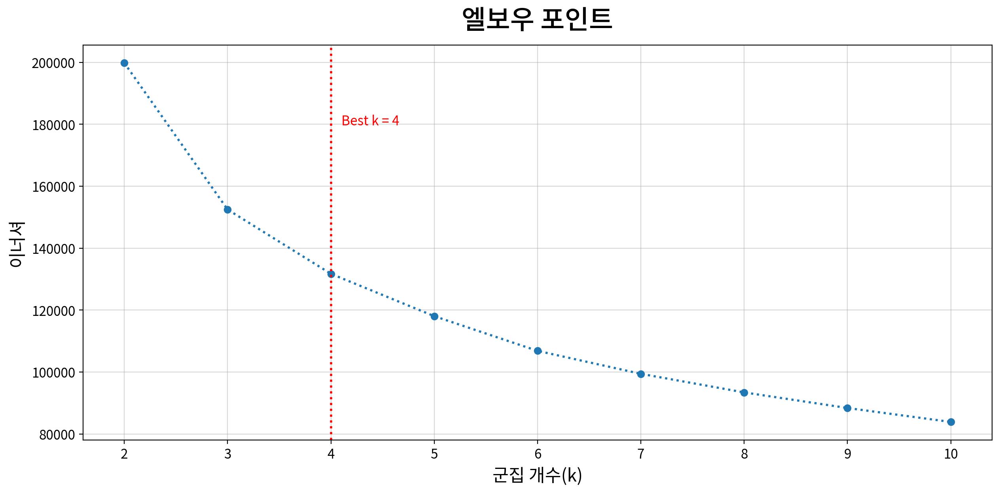

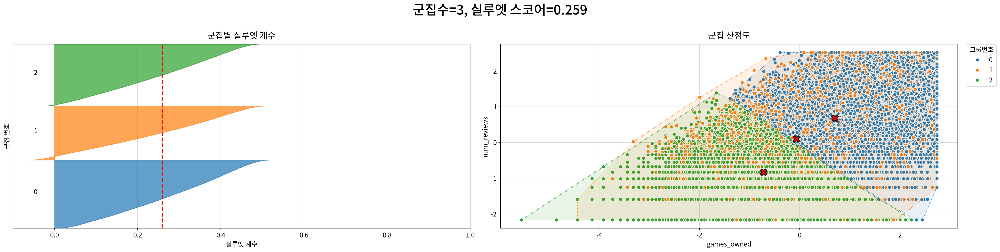

[1단계] 엘보우 포인트 : k = 4 (뭉침만 확인 → 후보)
[2단계] 실루엣 균형지수 : k = 3 (뭉침 + 분리 + 크기균형)
------------------------------------------------------------
두 지표가 다른 k를 가리킵니다.
 · k = 4 : 균형지수 0.0953 (스코어 0.2305, 두께비 1.7527)
 · k = 3 : 균형지수 0.169 (스코어 0.2588, 두께비 1.2641)
------------------------------------------------------------
>>> 최종 선택: k = 3
  (지표는 후보를 좁혀줄 뿐이므로, 목적과 도메인 지식으로 한 번 더 확인할 것)


In [ ]:
#final_k, result_df = my_cluster.best_k(df_log)

StandardScaler 적용 (4개 컬럼)
컬럼                            변환 전                  변환 후
--------------------------------------------------------
games_owned          0.00 ~ 8.15          -5.55 ~ 2.74
num_reviews          0.00 ~ 5.64          -2.17 ~ 2.52
playtime_at_review_min        1.61 ~ 10.57          -4.62 ~ 2.33
n_ach_at_review         0.00 ~ 4.42          -2.50 ~ 2.17


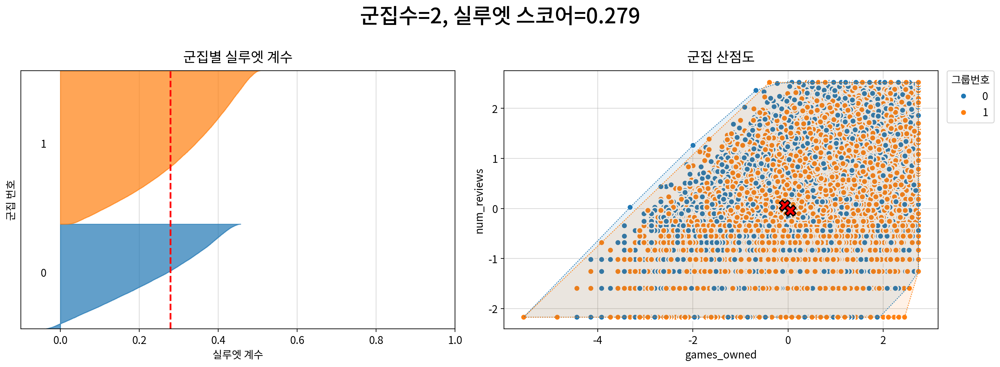

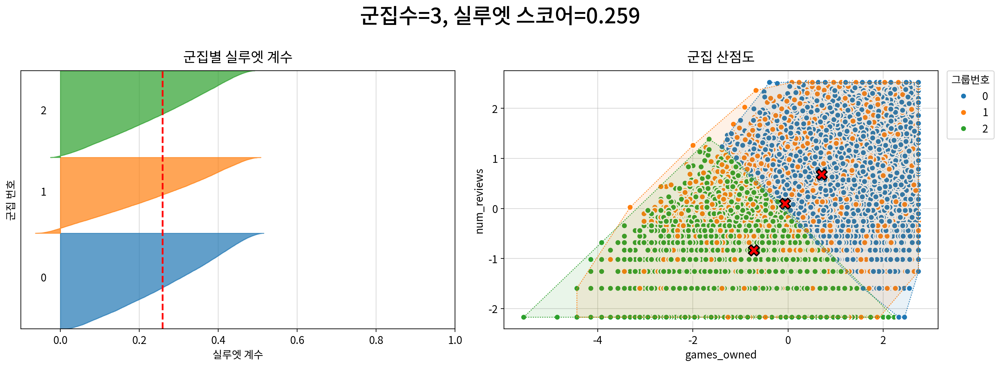

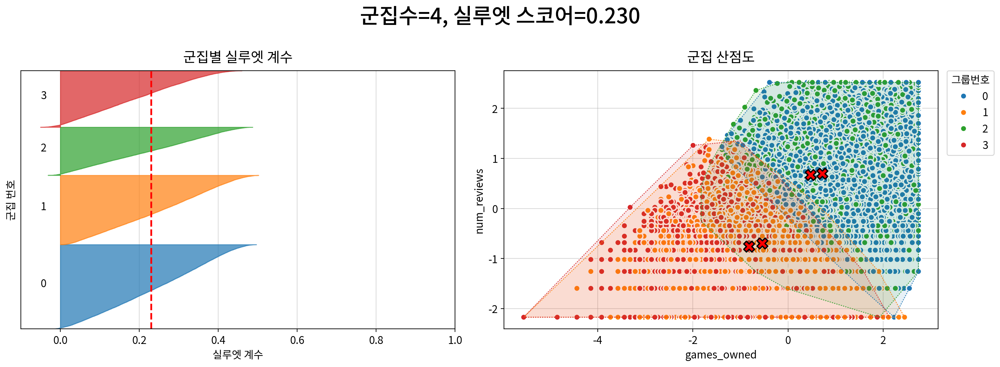

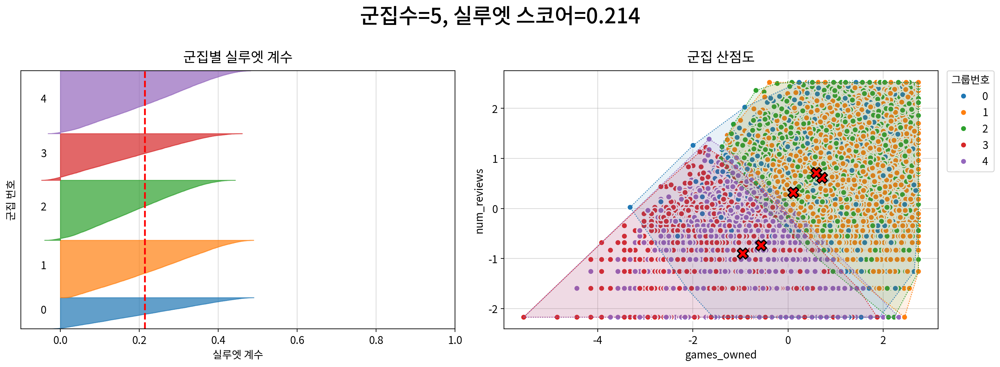

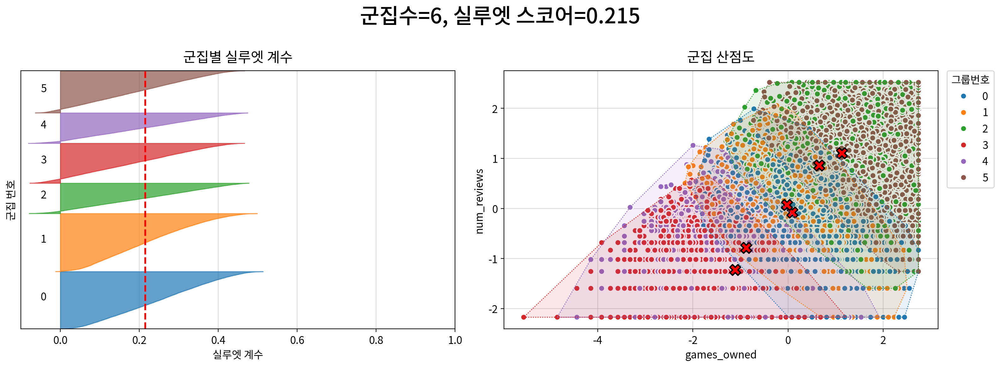

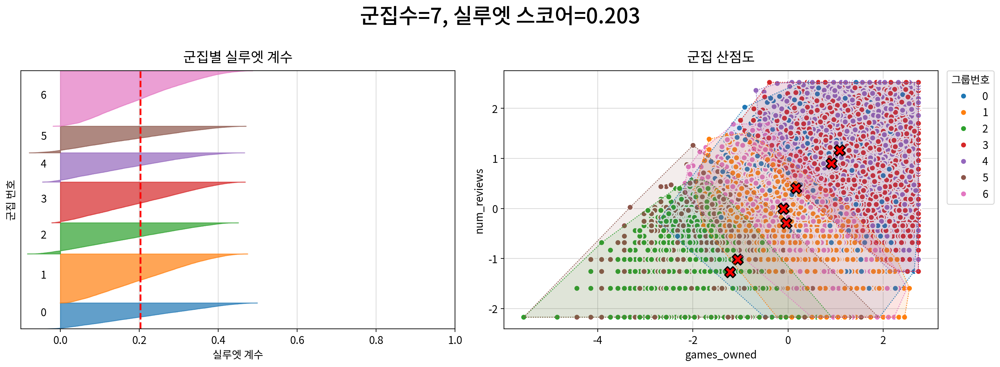

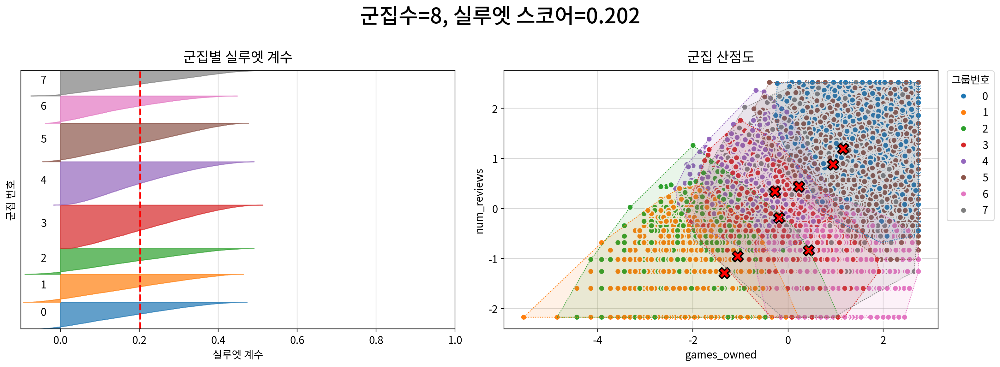

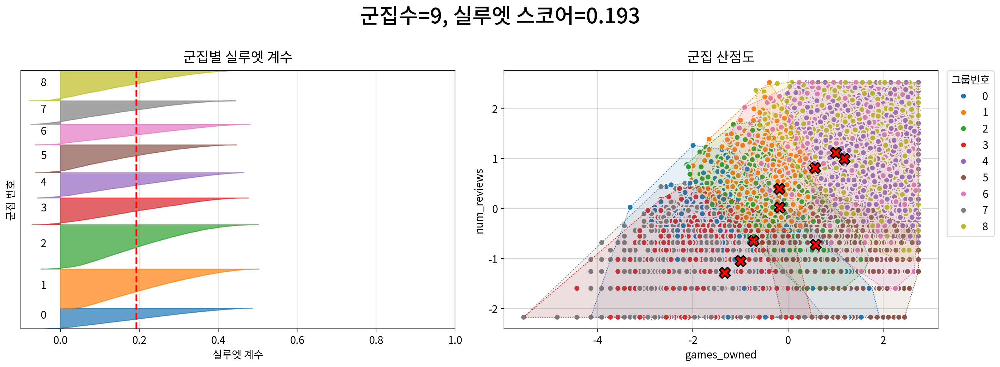

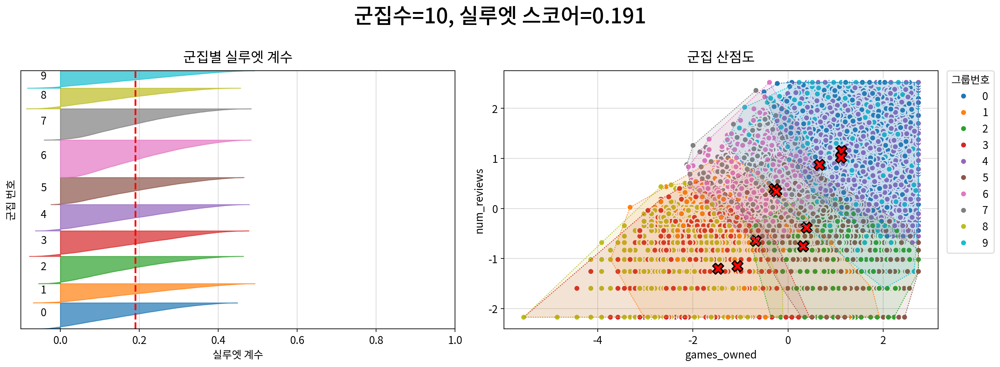

[실루엣] 균형지수 최대 → 최적의 k = 3 (스코어 0.2588, 두께비 1.2641, 균형지수 0.169)
실루엣 스코어가 가장 높은 K: 3


,k,스코어,전체면적,두께비,최소상대면적,균형지수
0,2,0.279,19789.913,1.463,0.684,0.131
1,3,0.259,18349.433,1.264,0.826,0.169
2,4,0.231,16345.422,1.753,0.725,0.095
3,5,0.214,15188.546,2.007,0.642,0.069
4,6,0.215,15225.978,1.913,0.684,0.077
5,7,0.203,14396.838,2.126,0.645,0.062
6,8,0.203,14357.201,1.724,0.681,0.080
7,9,0.193,13675.849,2.156,0.650,0.058
8,10,0.191,13518.799,2.150,0.671,0.059


In [51]:
# plot_each=True 설정시 모든 k에 대해 실루엣 계수를 시각화하고,
# plot_each=False 설정시 가장 좋은 k에 대해서만 시각화한다.
sil_k, sil_df = my_cluster.best_k_silhouette(df_log, plot_each=True)

print("실루엣 스코어가 가장 높은 K:", sil_k)
sil_df

StandardScaler 적용 (4개 컬럼)
컬럼                            변환 전                  변환 후
--------------------------------------------------------
games_owned          0.00 ~ 8.15          -5.55 ~ 2.74
num_reviews          0.00 ~ 5.64          -2.17 ~ 2.52
playtime_at_review_min        1.61 ~ 10.57          -4.62 ~ 2.33
n_ach_at_review         0.00 ~ 4.42          -2.50 ~ 2.17


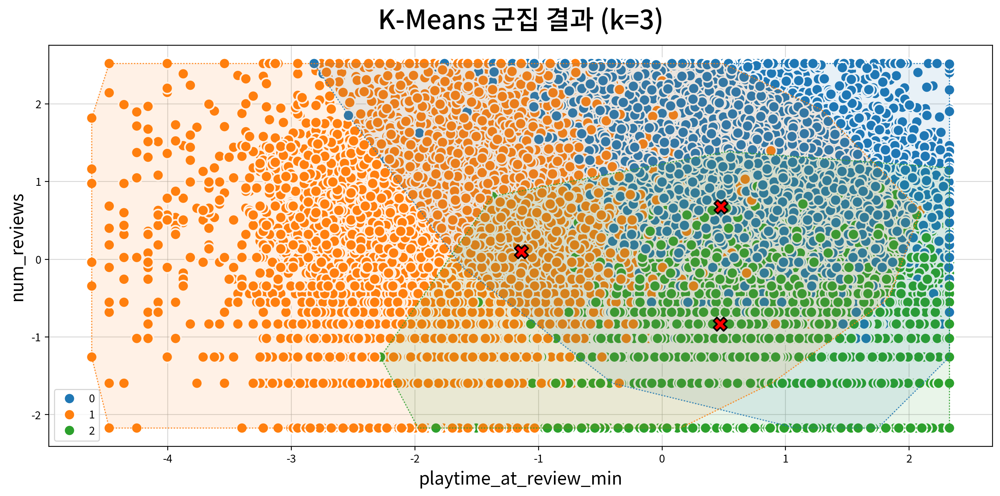

,games_owned,num_reviews,playtime_at_review_min,n_ach_at_review,그룹번호
0,0.402,-0.442,-0.254,-0.304,1
1,1.772,1.441,1.213,1.059,0
2,1.309,0.710,-0.002,-0.445,0
3,0.144,1.419,-1.874,-1.341,1
4,-0.427,0.080,-0.380,0.125,2


In [6]:
estimator, df, center_df = my_cluster.kmeans(df_log, k=3, x='playtime_at_review_min', y='num_reviews')
df.head()

In [7]:
#df_log = df_log.rename(columns={'playtime_at_review_min': 'playtime_at_review_min(로그·표준화)'})
#df_log = df_log.rename(columns={'games_owned': 'games_owned(로그·표준화)'})

StandardScaler 적용 (4개 컬럼)
컬럼                            변환 전                  변환 후
--------------------------------------------------------
games_owned          0.00 ~ 8.15          -5.55 ~ 2.74
num_reviews          0.00 ~ 5.64          -2.17 ~ 2.52
playtime_at_review_min        1.61 ~ 10.57          -4.62 ~ 2.33
n_ach_at_review         0.00 ~ 4.42          -2.50 ~ 2.17


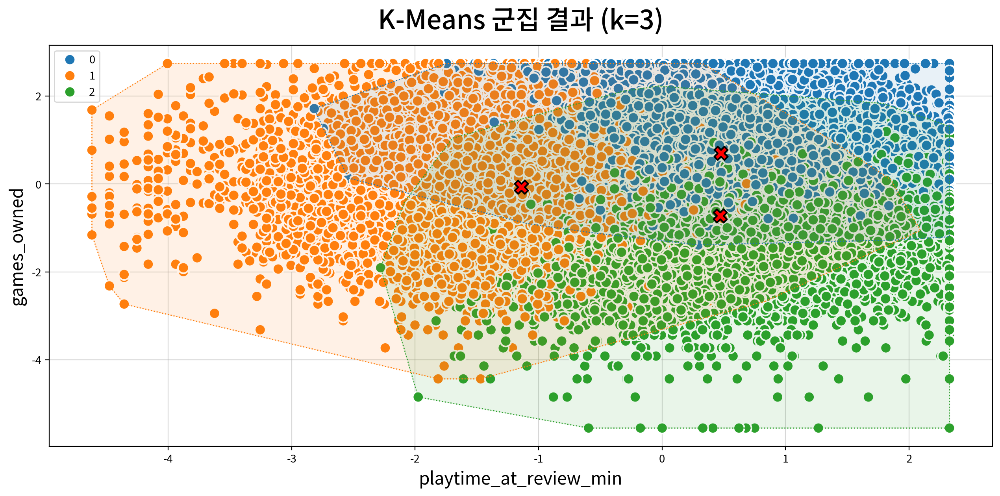

In [8]:
estimator, df, center_df = my_cluster.kmeans(df_log, k=3, x='playtime_at_review_min', y='games_owned')

In [9]:
df_group = origin.join(df['그룹번호'])
df_group.head(1)

,steamid,language,review,ts_created,ts_updated,voted_up,games_owned,num_reviews,playtime_forever_min,playtime_at_review_min,last_played,month,stage_final,n_ach_total,first_unlock,last_unlock,stage_at_review,n_ach_at_review,gap_days,playtime_after_review_min,mastery,그룹번호
0,76561198801410609,english,"Wide as a lake, deep as a puddle.",2023-09-06 00:00:29,2023-12-23 21:49:27,False,348.000,8.000,4535.000,1391.000,2026-04-14 17:29:47,2023-09,2,19,2023-09-01 12:02:37,2023-09-21 02:24:41,2,7,936.629,3144.000,0.251,1


In [10]:
df_oof = pd.read_csv(r'C:\Users\reqdr\Documents\VS works\Project3\추천확률.csv', encoding='utf-8-sig')
df_oof.head(1)

,steamid,추천확률
0,76561198801410609,0.839


In [11]:
# df_oof에서 기준 열(steamid)과 가져올 열들만 선택합니다.
cols_to_use = [
    "steamid", '추천확률'
]

# origin 데이터프레임 기준으로 병합합니다.
df_final = pd.merge(df_group, df_oof[cols_to_use], on="steamid", how="left")
df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 70915 entries, 0 to 70914
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   steamid                    70915 non-null  int64  
 1   language                   70915 non-null  str    
 2   review                     70915 non-null  str    
 3   ts_created                 70915 non-null  str    
 4   ts_updated                 70915 non-null  str    
 5   voted_up                   70915 non-null  bool   
 6   games_owned                70915 non-null  float64
 7   num_reviews                70915 non-null  float64
 8   playtime_forever_min       70915 non-null  float64
 9   playtime_at_review_min     70915 non-null  float64
 10  last_played                70915 non-null  str    
 11  month                      70915 non-null  str    
 12  stage_final                70915 non-null  int64  
 13  n_ach_total                70915 non-null  int64  
 14  f

In [12]:
time_cols = ['playtime_forever_min', 'playtime_at_review_min', 'playtime_after_review_min']
df_final[time_cols] = round(df_final[time_cols] / 60, 2)

In [13]:
df_final.groupby('그룹번호')[['games_owned', 'num_reviews', 'playtime_at_review_min', 'playtime_after_review_min', 'stage_at_review', 'n_ach_at_review', '추천확률']].describe().T

그룹번호                                    0         1         2
games_owned               count 26300.000 20805.000 23810.000
                          mean    621.332   326.644   150.137
                          std     574.148   377.247   115.563
                          min      60.000     3.000     1.000
                          25%     281.000   127.000    75.000
                          50%     431.000   220.000   124.000
                          75%     727.000   381.000   192.000
                          max    3466.720  3466.720  2097.000
num_reviews               count 26300.000 20805.000 23810.000
                          mean     44.930    27.107     6.923
                          std      47.243    35.408     5.732
                          min       1.000     1.000     1.000
                          25%      17.000     8.000     3.000
                          50%      29.000    16.000     5.000
                          75%      53.000    32.000     9.000
                          max     281.430   281.430    72.000
playtime_at_review_min    count 26300.000 20805.000 23810.000
                          mean     82.484    12.022    87.215
                          std      84.110    16.113   100.488
                          min       0.850     0.080     1.700
                          25%      34.620     3.970    33.030
                          50%      55.620     8.180    53.930
                          75%      97.385    14.650    98.195
                          max     647.030   477.520   647.030
playtime_after_review_min count 26300.000 20805.000 23810.000
                          mean     59.974    46.680    84.587
                          std     118.264   106.915   164.987
                          min       0.000     0.000     0.000
                          25%       0.650     0.180     2.950
                          50%      20.300     9.680    28.860
                          75%      68.335    51.150    88.178
                          max    1408.630  1430.730  1422.130
stage_at_review           count 26300.000 20805.000 23810.000
                          mean      5.254     1.712     5.228
                          std       3.402     0.839     3.375
                          min       0.000     0.000     0.000
                          25%       2.000     1.000     2.000
                          50%       4.000     2.000     4.000
                          75%      10.000     2.000    10.000
                          max      10.000    10.000    10.000
n_ach_at_review           count 26300.000 20805.000 23810.000
                          mean     19.723     3.169    19.148
                          std      12.550     2.178    12.369
                          min       0.000     0.000     0.000
                          25%       9.000     2.000     9.000
                          50%      17.000     3.000    16.000
                          75%      28.000     4.000    27.000
                          max      82.000    50.000    82.000
추천확률                      count 26300.000 20805.000 23810.000
                          mean      0.567     0.505     0.635
                          std       0.385     0.391     0.380
                          min       0.000     0.000     0.000
                          25%       0.136     0.084     0.215
                          50%       0.680     0.508     0.834
                          75%       0.950     0.928     0.973
                          max       1.000     1.000     1.000

In [14]:
# 추천확률에 따라 라벨링
# 조건이 참(> 0.5)이면 1, 거짓이면 0
df_final['추천라벨'] = np.where(df_final['추천확률'] > 0.5, 1, 0)

# pd.crosstab의 행(rownames) 쪽에 그룹번호를 리스트로 함께 묶어줍니다.
group_confusion = pd.crosstab(
    index=[df_final["그룹번호"], df_final["voted_up"]],  # 그룹별, 실제값별로 쪼개기
    columns=df_final["추천라벨"],  # 열은 예측값
    margins=False,  # 그룹별 비교를 위해 전체 총합은 제외 (원하시면 True로 변경 가능)
)

# 라벨 이름을 직관적으로 변경
group_confusion.index.names = ["그룹번호", "Actual (실제)"]
group_confusion.columns = ["비추천(0)", "추천(1)"]

group_confusion

비추천(0)  추천(1)
그룹번호 Actual (실제)               
0    False          9547   1648
     True           1551  13554
1    False          9321   1532
     True           1024   8928
2    False          7181   1144
     True           1121  14364

In [15]:
# 1. 600 미만 여부를 나타내는 불리언(True/False) 컬럼 생성
df_final['under_600'] = df_final['playtime_after_review_min'] < 600

# 2. '그룹번호'별로 묶어서 개수(sum)와 비율(mean)을 한 번에 계산
group_stats = df_final.groupby('그룹번호')['under_600'].agg(
    count='sum',     # 조건(True)을 만족하는 행의 총 개수
    ratio='mean'     # 전체 행 중 조건(True)을 만족하는 행의 비율 (0~1 사이)
).reset_index()

# 결과 출력
print(group_stats)

   그룹번호  count  ratio
0     0  26023  0.989
1     1  20671  0.994
2     2  23212  0.975


In [16]:
from scipy.stats import normaltest
# 1. normaltest 수행 (결측치 제외 옵션 적용)
stat, p_value = normaltest(df_final['추천확률'], nan_policy='omit')

print(f"검정 통계량(Statistic): {stat:.4f}")
print(f"p-value: {p_value}")

검정 통계량(Statistic): 340693.3603
p-value: 0.0


### # 페르소나 분석

In [17]:
# 군집을 만든 변수 (거리 계산에 사용)
cluster_columns = ['games_owned', 'num_reviews', 'playtime_at_review_min', 'n_ach_at_review']

# 군집을 설명할 변수 (군집화에 쓰지 않은 나이·성별도 포함한다)
num_columns = ['playtime_after_review_min', 'n_ach_total', 'mastery'] + cluster_columns
cat_columns = ['voted_up']

print("군집화 변수:", cluster_columns)
print("해석 - 연속형:", num_columns)
print("해석 - 범주형:", cat_columns)

군집화 변수: ['games_owned', 'num_reviews', 'playtime_at_review_min', 'n_ach_at_review']
해석 - 연속형: ['playtime_after_review_min', 'n_ach_total', 'mastery', 'games_owned', 'num_reviews', 'playtime_at_review_min', 'n_ach_at_review']
해석 - 범주형: ['voted_up']


In [18]:
from scipy.stats import normaltest
persona_list = []

# 1) 군집 수 만큼 반복
for i in range(0, 3):
    # 1-1) 현재 군집에 속한 데이터만 추출
    cluster_data = df_final[df_final["그룹번호"] == i]

    # 1-2) 군집별 요약 통계 생성
    persona_item = {"Cluster": i, "count": len(cluster_data)}

    # 1-3) 연속형 변수: 정규분포면 평균, 아니면 중앙값
    for column in num_columns:
        stat, p = normaltest(cluster_data[column])  # 정규성 검정

        if p > 0.05:    # 정규분포를 따르면 평균값
            persona_item[column] = round(cluster_data[column].mean(), 3)
            print(f"군집{i} - {column} : 정규분포를 따름 (p={p:.3f}) → 평균값 사용")
        else:           # 정규분포를 따르지 않으면 중앙값
            persona_item[column] = round(cluster_data[column].median(), 3)
            print(f"군집{i} - {column} : 정규분포를 따르지 않음 (p={p:.3f}) → 중앙값 사용")

    # 1-4) 범주형 변수: 최빈값
    for column in cat_columns:
        persona_item[column] = cluster_data[column].value_counts().idxmax()
        print(f"군집{i} - {column} : 최반값 = {persona_item[column]}")

    # 1-5) 결과 리스트에 추가
    persona_list.append(persona_item)

# 2) 결과 확인
# 데이터프레임으로 변환하고 군집 번호 기준으로 정렬
persona_df = DataFrame(persona_list).sort_values(by="Cluster")
persona_df

군집0 - playtime_after_review_min : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집0 - n_ach_total : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집0 - mastery : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집0 - games_owned : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집0 - num_reviews : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집0 - playtime_at_review_min : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집0 - n_ach_at_review : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집0 - voted_up : 최반값 = True
군집1 - playtime_after_review_min : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집1 - n_ach_total : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집1 - mastery : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집1 - games_owned : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집1 - num_reviews : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집1 - playtime_at_review_min : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집1 - n_ach_at_review : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집1 - voted_up : 최반값 = False
군집2 - playtime_after_review_min : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집2 - n_ach_total : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용
군집2 - mastery : 정규분포를 따르지 않음 (p=0.000) → 중앙값 사용

,Cluster,count,playtime_after_review_min,n_ach_total,mastery,games_owned,num_reviews,playtime_at_review_min,n_ach_at_review,voted_up
0,0,26300,20.300,29.000,0.277,431.000,29.000,55.620,17.000,True
1,1,20805,9.680,6.000,0.324,220.000,16.000,8.180,3.000,False
2,2,23810,28.860,28.500,0.253,124.000,5.000,53.930,16.000,True


## # 페르소나 x 추천확률 분석

### 1. 누가 : 페르소나 x 추천확률

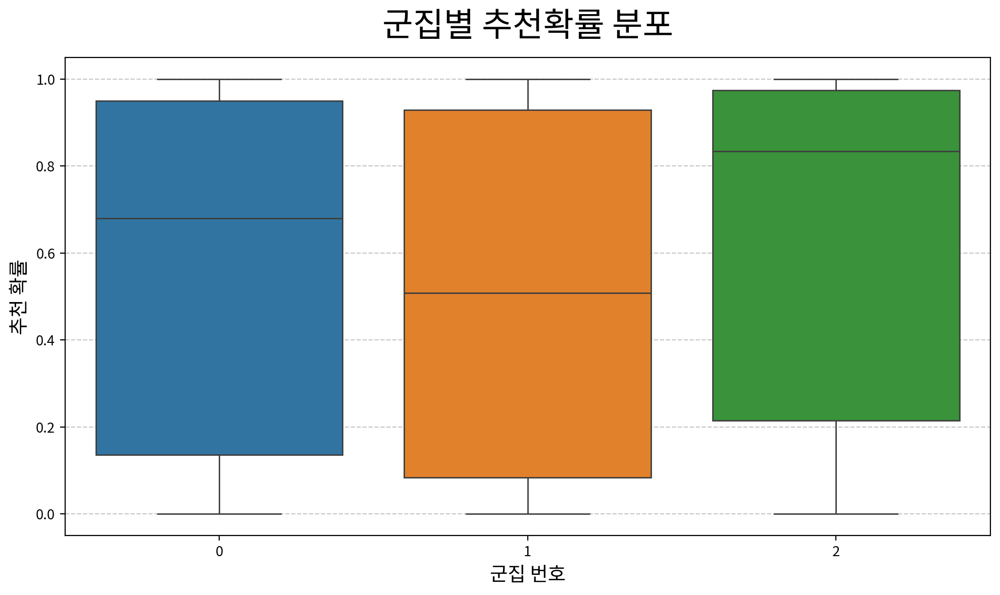

In [19]:
plt.figure(figsize=(10, 6))

sb.boxplot(data=df_final, x='그룹번호', y='추천확률', hue='그룹번호', palette='tab10', legend=False)

plt.title('군집별 추천확률 분포', pad=15)
plt.xlabel('군집 번호')
plt.ylabel('추천 확률')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 범례 텍스트를 순서대로 리스트로 작성합니다.
#new_labels = ['0 하드 리뷰어', '1 초기 리뷰어', '2 라이트 리뷰어']

# labels 인자에 새 리스트를 넘겨주고, 기존처럼 그래프 바깥으로 뺍니다.
#plt.legend(title='군집 분류', labels=new_labels, loc='upper left', bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

### 2. 어디서

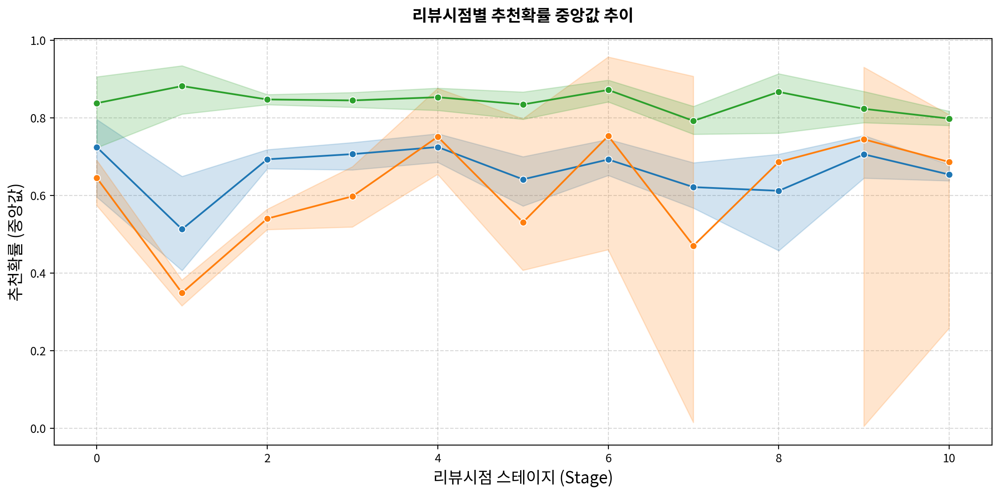

In [20]:
plt.figure(figsize=(12, 6))

# x축: 리뷰 시점, y축: 추천확률, hue: 그룹별로 선 분리
# marker='o'를 추가하면 각 시점(점)이 명확히 보입니다.
sb.lineplot(
    data=df_final, 
    x='stage_at_review', 
    y='추천확률', 
    hue='그룹번호',
    estimator='median', 
    marker='o', 
    palette='tab10',
    legend=False
)

plt.title('리뷰시점별 추천확률 중앙값 추이', pad=15, fontsize=14, fontweight='bold')
plt.xlabel('리뷰시점 스테이지 (Stage)')
plt.ylabel('추천확률 (중앙값)')
plt.grid(axis='both', linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()

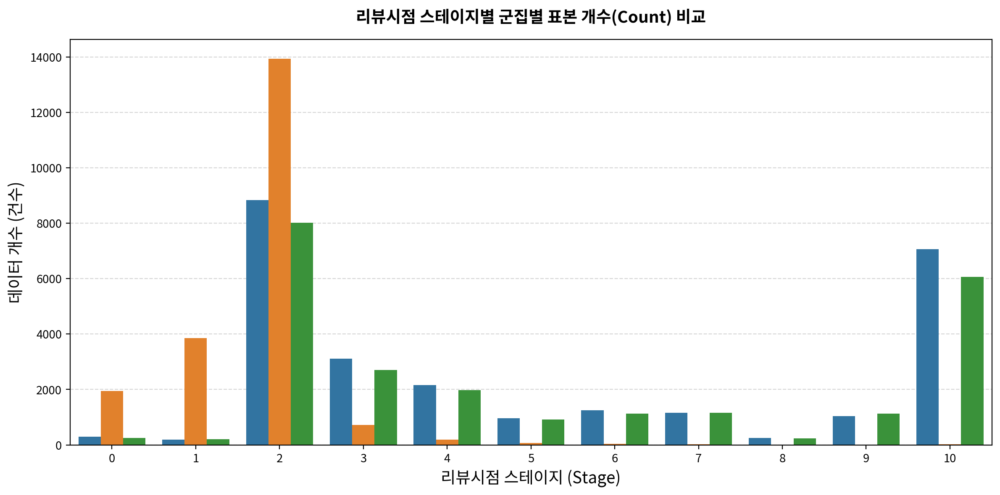

In [21]:
plt.figure(figsize=(12, 6))

# x축은 리뷰 시점, hue로 그룹을 나누면 y축은 자동으로 데이터 개수(Count)가 됩니다.
sb.countplot(
    data=df_final, 
    x='stage_at_review', 
    hue='그룹번호', 
    palette='tab10',
    legend=False
)

plt.title('리뷰시점 스테이지별 군집별 표본 개수(Count) 비교', pad=15, fontsize=14, fontweight='bold')
plt.xlabel('리뷰시점 스테이지 (Stage)')
plt.ylabel('데이터 개수 (건수)')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

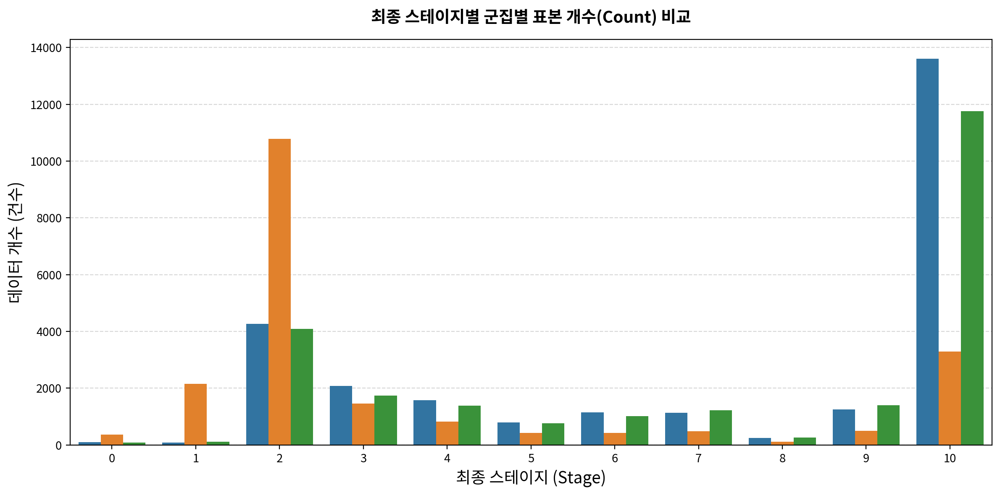

In [22]:
plt.figure(figsize=(12, 6))

# x축은 리뷰 시점, hue로 그룹을 나누면 y축은 자동으로 데이터 개수(Count)가 됩니다.
sb.countplot(
    data=df_final, 
    x='stage_final', 
    hue='그룹번호', 
    palette='tab10',
    legend=False
)

plt.title('최종 스테이지별 군집별 표본 개수(Count) 비교', pad=15, fontsize=14, fontweight='bold')
plt.xlabel('최종 스테이지 (Stage)')
plt.ylabel('데이터 개수 (건수)')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [23]:
# 'stage_at_review'와 '그룹번호'별로 추천확률의 데이터 개수(count)와 평균(mean) 확인
df_counts = df_final.groupby(['stage_at_review', '그룹번호'])['추천확률'].agg(['count', 'mean']).reset_index()

# 8스테이지 근처 데이터만 필터링해서 출력
print(df_counts[df_counts['stage_at_review'].isin([7, 8, 9])])

    stage_at_review  그룹번호  count  mean
21                7     0   1154 0.547
22                7     1     19 0.460
23                7     2   1165 0.614
24                8     0    247 0.526
25                8     1      1 0.686
26                8     2    232 0.661
27                9     0   1043 0.574
28                9     1      5 0.509
29                9     2   1135 0.638


In [24]:
# 조건 리스트 정의 (미만, 이상~미만, 이상)
conditions = [
    df_final['추천확률'] < 0.3,
    (df_final['추천확률'] >= 0.3) & (df_final['추천확률'] < 0.7),
    df_final['추천확률'] >= 0.7
]

# 조건에 매칭될 값 리스트 (0, 1, 2)
choices = [0, 1, 2]

# 조건에 맞게 새로운 열 생성
df_final['추천확률_구간'] = np.select(conditions, choices, default=np.nan)

--- 그룹별 구간 데이터 개수 ---
추천확률_구간  0.000  1.000  2.000
그룹번호                        
0         9005   4397  12898
1         8649   3403   8753
2         6781   3304  13725

--- 그룹별 구간 내 비율 (%) ---
추천확률_구간  0.000  1.000  2.000
그룹번호                        
0       34.200 16.700 49.000
1       41.600 16.400 42.100
2       28.500 13.900 57.600


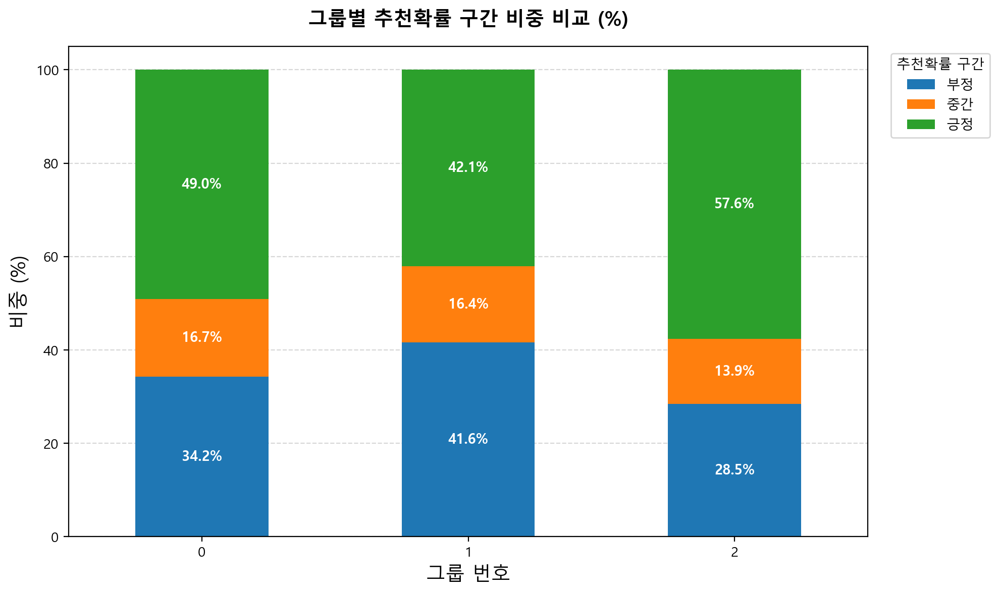

In [25]:
tab10_colors = plt.get_cmap('tab10').colors[:3]

# 1. 그룹별 구간 데이터 개수 확인
cross_count = pd.crosstab(df_final['그룹번호'], df_final['추천확률_구간'])
print("--- 그룹별 구간 데이터 개수 ---")
print(cross_count)

# 2. 그룹별 구간 데이터 비율(%) 확인 (행 기준 100% 집계)
cross_rate = pd.crosstab(df_final['그룹번호'], df_final['추천확률_구간'], normalize='index') * 100
print("\n--- 그룹별 구간 내 비율 (%) ---")
print(cross_rate.round(1))

import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 위에서 구한 행 기준 백분율 데이터로 그래프 생성
# 컬럼 이름(0, 1, 2)을 알기 쉽게 매핑
cross_rate.columns = ['부정', '중간', '긍정']

# 누적 막대그래프 시각화
ax = cross_rate.plot(kind='bar', stacked=True, figsize=(10, 6), color=tab10_colors)

plt.title('그룹별 추천확률 구간 비중 비교 (%)', pad=15, fontsize=14, fontweight='bold')
plt.xlabel('그룹 번호')
plt.ylabel('비중 (%)')
plt.xticks(rotation=0) # x축 글자 회전 방지
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 범례 위치 조절 및 겹침 방지 (이전 피드백 반영)
plt.legend(title='추천확률 구간', loc='upper left', bbox_to_anchor=(1.02, 1))

# 막대 내부에 실제 % 수치 적어주기
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 5: # 비중이 5% 이상인 경우에만 텍스트 표시
        x, y = p.get_xy() 
        ax.annotate(f'{height:.1f}%', (x + width/2, y + height/2), 
                    ha='center', va='center', fontsize=10, fontweight='bold', color='white')

plt.tight_layout()
plt.show()

In [26]:
# 그룹번호와 voted_up 별로 추천확률 중앙값 동시 집계
comparison_df = df_final.groupby(['그룹번호', 'voted_up'])['추천확률'].median().reset_index(name='추천확률_중앙값')
comparison_df

,그룹번호,voted_up,추천확률_중앙값
0,0,False,0.101
1,0,True,0.931
2,1,False,0.097
3,1,True,0.933
4,2,False,0.104
5,2,True,0.954


In [27]:
# 전체 대비 비율을 정확하게 구하기 위해 그룹별로 집계합니다.
summary_df = df_final.groupby('그룹번호').agg(
    전체건수=('그룹번호', 'count'),
    케이스A_건수=('voted_up', lambda x: ((df_final.loc[x.index, '추천확률_구간'] == 0) & (x == 1)).sum()),
    케이스B_건수=('voted_up', lambda x: ((df_final.loc[x.index, '추천확률_구간'] == 2) & (x == 0)).sum())
).reset_index()

# 그룹 내 비율(%) 계산 (소수점 둘째 자리까지 반올림)
summary_df['케이스A_비율(%)'] = round((summary_df['케이스A_건수'] / summary_df['전체건수']) * 100, 2)
summary_df['케이스B_비율(%)'] = round((summary_df['케이스B_건수'] / summary_df['전체건수']) * 100, 2)

# 결과 출력
print(summary_df[['그룹번호', '케이스A_건수', '케이스A_비율(%)', '케이스B_건수', '케이스B_비율(%)']])

   그룹번호  케이스A_건수  케이스A_비율(%)  케이스B_건수  케이스B_비율(%)
0     0      734       2.790      775       2.950
1     1      514       2.470      719       3.460
2     2      527       2.210      514       2.160


In [28]:
# 케이스 정의
df_final.loc[(df_final['voted_up'] == 1), '유저_유형'] = '일반 추천'
df_final.loc[(df_final['voted_up'] == 0), '유저_유형'] = '일반 비추천'
df_final.loc[(df_final['추천확률_구간'] == 0) & (df_final['voted_up'] == 1), '유저_유형'] = '불일치 추천'
df_final.loc[(df_final['추천확률_구간'] == 2) & (df_final['voted_up'] == 0), '유저_유형'] = '불일치 비추천'

# 그룹번호와 유저_유형별로 플레이 시간 평균 집계 (시간 단위 열 사용)
playtime_analysis = df_final.groupby(['그룹번호', '유저_유형']).agg(
    유저수=('유저_유형', 'count'),
    중간값_리뷰시점_플레이시간=('playtime_at_review_min', 'median'),
    중간값_리뷰이후_플레이시간=('playtime_after_review_min', 'median'),
    중간값_총_플레이시간=('playtime_forever_min', 'median')
).round(1).reset_index()

print(playtime_analysis)

    그룹번호    유저_유형    유저수  중간값_리뷰시점_플레이시간  중간값_리뷰이후_플레이시간  중간값_총_플레이시간
0      0  불일치 비추천    775          54.100           6.700       81.400
1      0   불일치 추천    734          61.100          23.700      106.700
2      0   일반 비추천  10420          59.400           1.900       78.400
3      0    일반 추천  14371          53.000          39.900      112.000
4      1  불일치 비추천    719           7.000           1.400       13.700
5      1   불일치 추천    514           7.200          23.400       36.300
6      1   일반 비추천  10134           6.800           1.000       11.800
7      1    일반 추천   9438          10.000          35.400       50.500
8      2  불일치 비추천    514          49.600           4.800       72.700
9      2   불일치 추천    527          56.700          31.600      104.800
10     2   일반 비추천   7811          58.200           2.700       77.400
11     2    일반 추천  14958          52.100          49.000      118.600


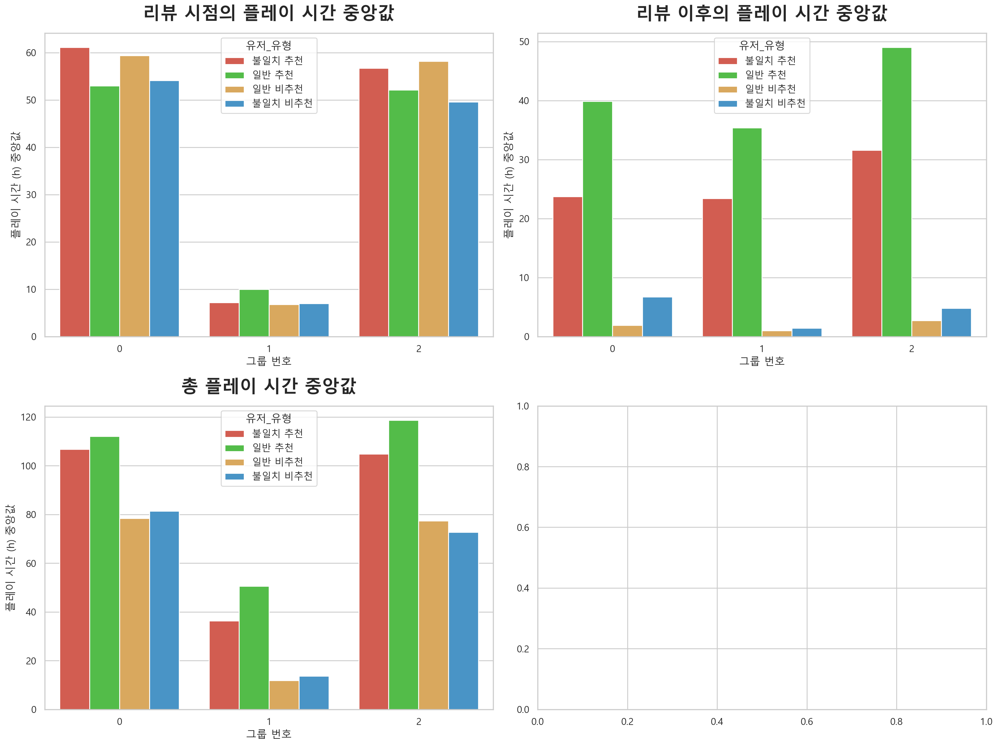

In [29]:
# 1. 한글 폰트 설정 및 유니코드 마이너스 깨짐 방지
plt.rc('font', family='Malgun Gothic')  # 맥북인 경우 'AppleGothic'으로 변경
plt.rcParams['axes.unicode_minus'] = False

# 2. Seaborn 스타일 테마 적용 (격자선 추가로 가독성 향상)
sb.set_theme(style="whitegrid", font="Malgun Gothic")

# 3. 그래프 그리기 (1행 2열 구조)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 데이터 유형별 일관된 색상 부여를 위한 팔레트 지정
custom_palette = {
    '일반 추천': "#43cf36",       
    '일반 비추천': "#eeac49",       
    '불일치 추천': '#e74c3c',   # 강조용 빨간색
    '불일치 비추천': '#3498db'  # 파란색
}

bar_order = ['불일치 추천', '일반 추천', '일반 비추천', '불일치 비추천']

# [좌측 그래프] 리뷰 시점 플레이 시간
sb.barplot(
    data=playtime_analysis, 
    x='그룹번호', 
    y='중간값_리뷰시점_플레이시간', 
    hue='유저_유형', 
    hue_order=bar_order,
    ax=axes[0, 0], 
    palette=custom_palette
)
axes[0, 0].set_title('리뷰 시점의 플레이 시간 중앙값', fontsize=20, fontweight='bold', pad=15)
axes[0, 0].set_xlabel('그룹 번호', fontsize=12)
axes[0, 0].set_ylabel('플레이 시간 (h) 중앙값', fontsize=12)

# [우측 그래프] 리뷰 이후 플레이 시간 (가설 검증의 핵심)
sb.barplot(
    data=playtime_analysis, 
    x='그룹번호', 
    y='중간값_리뷰이후_플레이시간', 
    hue='유저_유형', 
    hue_order=bar_order,
    ax=axes[0, 1], 
    palette=custom_palette
)
axes[0, 1].set_title('리뷰 이후의 플레이 시간 중앙값', fontsize=20, fontweight='bold', pad=15)
axes[0, 1].set_xlabel('그룹 번호', fontsize=12)
axes[0, 1].set_ylabel('플레이 시간 (h) 중앙값', fontsize=12)

# [좌측하단 그래프] 총 플레이 시간
sb.barplot(
    data=playtime_analysis, 
    x='그룹번호', 
    y='중간값_총_플레이시간', 
    hue='유저_유형', 
    hue_order=bar_order,
    ax=axes[1, 0], 
    palette=custom_palette
)
axes[1, 0].set_title('총 플레이 시간 중앙값', fontsize=20, fontweight='bold', pad=15)
axes[1, 0].set_xlabel('그룹 번호', fontsize=12)
axes[1, 0].set_ylabel('플레이 시간 (h) 중앙값', fontsize=12)

# 4. 레이아웃 조정 및 출력
plt.tight_layout()
plt.show()

In [30]:
# 그룹번호와 추천확률_구간별로 이변량 집계 수행
group_interval_analysis = df_final.groupby(['그룹번호', '추천확률_구간']).agg(
    유저수=('playtime_after_review_min', 'count'),
    평균_리뷰이후_시간=('playtime_after_review_min', 'mean'),
    중앙값_리뷰이후_시간=('playtime_after_review_min', 'median')
).round(1).reset_index()

# 결과를 보기 좋게 피벗 테이블 형태로 전환 (가로축: 추천확률_구간, 세로축: 그룹번호)
pivot_summary = group_interval_analysis.pivot(
    index='그룹번호', 
    columns='추천확률_구간', 
    values='평균_리뷰이후_시간'
)

print("■ 그룹별/구간별 리뷰 이후 평균 플레이 시간 (Hour) ■")
print(pivot_summary)
print("\n■ 전체 상세 데이터 ■")
print(group_interval_analysis)

■ 그룹별/구간별 리뷰 이후 평균 플레이 시간 (Hour) ■
추천확률_구간  0.000  1.000   2.000
그룹번호                         
0       30.400 54.200  82.600
1       21.000 37.400  75.700
2       38.600 65.500 111.900

■ 전체 상세 데이터 ■
   그룹번호  추천확률_구간    유저수  평균_리뷰이후_시간  중앙값_리뷰이후_시간
0     0    0.000   9005      30.400        1.900
1     0    1.000   4397      54.200       18.000
2     0    2.000  12898      82.600       39.100
3     1    0.000   8649      21.000        1.100
4     1    1.000   3403      37.400        7.200
5     1    2.000   8753      75.700       33.900
6     2    0.000   6781      38.600        2.900
7     2    1.000   3304      65.500       20.300
8     2    2.000  13725     111.900       48.800


In [31]:
# [분석 1] 그룹번호별 리뷰 이후 플레이 시간 집계
group_summary = df_final.groupby('그룹번호').agg(
    유저수=('playtime_after_review_min', 'count'),
    평균_플레이시간=('playtime_after_review_min', 'mean'),
    중앙값_플레이시간=('playtime_after_review_min', 'median')
).round(1).reset_index()

# [분석 2] 추천확률_구간별 리뷰 이후 플레이 시간 집계
interval_summary = df_final.groupby('추천확률_구간').agg(
    유저수=('playtime_after_review_min', 'count'),
    평균_플레이시간=('playtime_after_review_min', 'mean'),
    중앙값_플레이시간=('playtime_after_review_min', 'median')
).round(1).reset_index()

print("=== [분석 1] 그룹번호별 리뷰 이후 플레이 시간 ===")
print(group_summary.to_string(index=False))

print("\n=== [분석 2] 추천확률_구간별 리뷰 이후 플레이 시간 ===")
print(interval_summary.to_string(index=False))

=== [분석 1] 그룹번호별 리뷰 이후 플레이 시간 ===
 그룹번호   유저수  평균_플레이시간  중앙값_플레이시간
    0 26300    60.000     20.300
    1 20805    46.700      9.700
    2 23810    84.600     28.900

=== [분석 2] 추천확률_구간별 리뷰 이후 플레이 시간 ===
 추천확률_구간   유저수  평균_플레이시간  중앙값_플레이시간
   0.000 24435    29.300      1.700
   1.000 11104    52.400     14.300
   2.000 35376    92.300     41.300


C:\Users\reqdr\AppData\Local\Temp\ipykernel_16520\2685456835.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(
C:\Users\reqdr\AppData\Local\Temp\ipykernel_16520\2685456835.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sb.barplot(


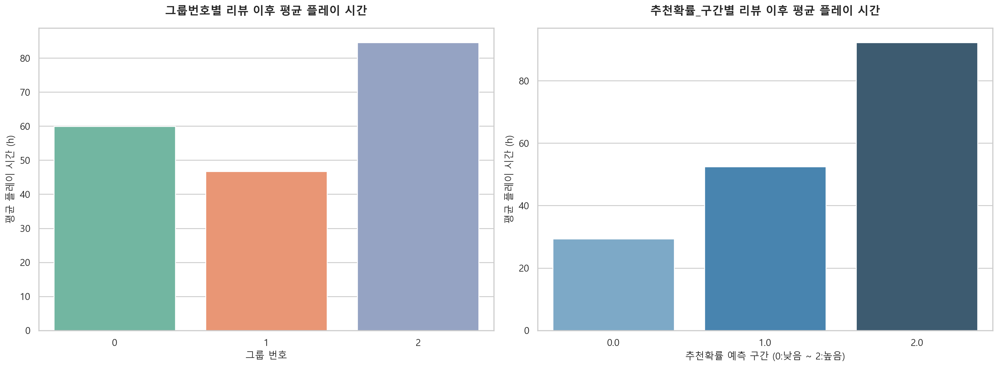

In [32]:
# 한글 폰트 및 스타일 초기화
plt.rc('font', family='Malgun Gothic')  # 맥북은 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
sb.set_theme(style="whitegrid", font="Malgun Gothic")

# 1행 2열 서브플롯 생성
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# [좌측 그래프] 그룹번호별 비교
sb.barplot(
    data=df_final, 
    x='그룹번호', 
    y='playtime_after_review_min', 
    ax=axes[0], 
    palette='Set2', 
    errorbar=None
)
axes[0].set_title('그룹번호별 리뷰 이후 평균 플레이 시간', fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel('그룹 번호', fontsize=11)
axes[0].set_ylabel('평균 플레이 시간 (h)', fontsize=11)

# [우측 그래프] 추천확률_구간별 비교
sb.barplot(
    data=df_final, 
    x='추천확률_구간', 
    y='playtime_after_review_min', 
    ax=axes[1], 
    palette='Blues_d', 
    errorbar=None
)
axes[1].set_title('추천확률_구간별 리뷰 이후 평균 플레이 시간', fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel('추천확률 예측 구간 (0:낮음 ~ 2:높음)', fontsize=11)
axes[1].set_ylabel('평균 플레이 시간 (h)', fontsize=11)

plt.tight_layout()
plt.show()

In [33]:
df_final['playtime_after_review_min'].describe()

count   70915.000
mean       64.338
std       133.850
min         0.000
25%         0.850
50%        19.720
75%        69.390
max      1430.730
Name: playtime_after_review_min, dtype: float64

In [34]:
# 1. 한국어 유저(koreana) 그룹별 추천확률 중간값
kor_df = df_final[df_final['language'] == 'koreana']
kor_summary = kor_df.groupby('그룹번호')['추천확률'].median().reset_index()
kor_summary.columns = ['그룹번호', '한국어_추천확률_중간값']

# 2. 한국어 제외 타언어 유저 그룹별 추천확률 중간값
other_lang_df = df_final[df_final['language'] != 'koreana']
other_summary = other_lang_df.groupby('그룹번호')['추천확률'].median().reset_index()
other_summary.columns = ['그룹번호', '타언어_추천확률_중간값']

# 3. 두 데이터 병합 및 차이(Gap) 계산
lang_analysis = pd.merge(other_summary, kor_summary, on='그룹번호', how='left')
lang_analysis['차이(%p)'] = (lang_analysis['한국어_추천확률_중간값'] - lang_analysis['타언어_추천확률_중간값']) * 100
lang_analysis = lang_analysis.round(3)

print("■ 언어별/그룹별 추천확률 중간값 비교 (한국어 vs 타언어) ■")
print(lang_analysis.to_string(index=False))

■ 언어별/그룹별 추천확률 중간값 비교 (한국어 vs 타언어) ■
 그룹번호  타언어_추천확률_중간값  한국어_추천확률_중간값  차이(%p)
    0         0.683         0.527 -15.674
    1         0.513         0.358 -15.434
    2         0.837         0.443 -39.371


In [35]:
# 앞서 정의한 명칭('케이스A_애증그룹')에 맞는 행만 필터링
love_hate_reviews = df_final[df_final['유저_유형'] == '부정·추천']['review'].dropna()

# 1. 화면에 상위 5개 리뷰 깔끔하게 출력하기
print(f"■ 애증그룹 유저들의 실제 리뷰 샘플 (총 {len(love_hate_reviews)}건) ■\n")
for i, review in enumerate(love_hate_reviews.head(10), 1):
    print(f"[{i}번째 애증 유저 리뷰]")
    print(review)
    print("-" * 50)

■ 애증그룹 유저들의 실제 리뷰 샘플 (총 0건) ■



In [36]:
# 앞서 정의한 명칭('케이스A_애증그룹')에 맞는 행만 필터링
love_hate_reviews = df_final[df_final['유저_유형'] == '긍정·비추천']['review'].dropna()

# 1. 화면에 상위 5개 리뷰 깔끔하게 출력하기
print(f"■ 이탈위험군 유저들의 실제 리뷰 샘플 (총 {len(love_hate_reviews)}건) ■\n")
for i, review in enumerate(love_hate_reviews.head(20), 1):
    print(f"[{i}번째 이탈위험군 유저 리뷰]")
    print(review)
    print("-" * 50)

■ 이탈위험군 유저들의 실제 리뷰 샘플 (총 0건) ■



In [37]:
# 1. 리뷰 데이터 문자열 길이 계산 (결측치는 빈 문자열 처리)
df_final['review_length'] = df_final['review'].fillna('').astype(str).str.len()

# 2. 특정 그룹(애증, 이탈) 통계 집계
target_groups = ['애증그룹', '이탈위험군', '일반유저']
df_filtered = df_final[df_final['유저_유형'].isin(target_groups)]
group_summary = df_filtered.groupby('유저_유형')['review_length'].agg(
    유저수='count',
    평균_글자수='mean',
    중앙값_글자수='median',
    최대_글자수='max'
).reset_index()

# 3. 전체 유저 대조군 통계 집계 및 가공
total_summary = pd.DataFrame([{
    '유저_유형': '전체 유저 (All)',
    '유저수': len(df_final),
    '평균_글자수': df_final['review_length'].mean(),
    '중앙값_글자수': df_final['review_length'].median(),
    '최대_글자수': df_final['review_length'].max()
}])

# 4. 두 표 병합 및 소수점 정리
final_length_summary = pd.concat([total_summary, group_summary], ignore_index=True).round(1)

print("■ [전체 유저 포함] 유형별 리뷰 글자 수 통계 ■")
print(final_length_summary.to_string(index=False))

■ [전체 유저 포함] 유형별 리뷰 글자 수 통계 ■
      유저_유형   유저수  평균_글자수  중앙값_글자수  최대_글자수
전체 유저 (All) 70915 444.300   98.000    8000


In [38]:
# 1. 리뷰 데이터 문자열 길이 계산 (결측치는 빈 문자열 처리)
df_final['review_length'] = df_final['review'].fillna('').astype(str).str.len()

# 2. 5글자 미만 여부를 판별하는 조건 열 생성 (True/False)
df_final['is_short_review'] = df_final['review_length'] < 5

# 3. 특정 그룹(애증, 이탈) 데이터 필터링
target_groups = ['애증그룹', '이탈위험군']
df_filtered = df_final[df_final['유저_유형'].isin(target_groups)]

# 4. 유저_유형별 짧은 리뷰 건수 및 비율 집계
group_short_summary = df_filtered.groupby('유저_유형')['is_short_review'].agg(
    전체유저수='count',
    짧은리뷰건수='sum',
    짧은리뷰비율_pct=lambda x: round((x.sum() / x.count()) * 100, 2)
).reset_index()

# 5. 전체 유저 대조군의 짧은 리뷰 비율 집계
total_short_summary = pd.DataFrame([{
    '유저_유형': '전체 유저 (All)',
    '전체유저수': len(df_final),
    '짧은리뷰건수': df_final['is_short_review'].sum(),
    '짧은리뷰비율_pct': round((df_final['is_short_review'].sum() / len(df_final)) * 100, 2)
}])

# 6. 두 표 병합
final_short_summary = pd.concat([total_short_summary, group_short_summary], ignore_index=True)

print("■ [5글자 미만] 유저 유형별 짧은 리뷰 비율 ■")
print(final_short_summary.to_string(index=False))

■ [5글자 미만] 유저 유형별 짧은 리뷰 비율 ■
      유저_유형  전체유저수  짧은리뷰건수  짧은리뷰비율_pct
전체 유저 (All)  70915    3789       5.340
